# 08 - Advanced optimization, algorithms, and constraints

This notebook extends optimization with algorithm-loop execution, feasibility filtering, and Pareto-oriented plotting.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, path configuration, and baseline model loading.
- Configuration: output selection, parameter definitions, and problem setup.
- Execution and review: simulation or optimization calls followed by targeted checks.

Main classes, methods, and functions used in this notebook:
- `OptimisationSimulation.run_optimisation`
- `OptimisationSimulation.plot_pareto_front`
- `OptimisationSimulation.set_problem`
- `ef.get_building`
- `OptimisationSimulation`
- `optim.discover_available_outputs`
- `optim.select_outputs`
- `optim.apply_outputs_preflight`
- `optim.set_output_readers`
- `optim.set_parameters`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## Advanced optimization: import workflow dependencies

We start by importing the APIs required for this notebook block.

Keeping imports explicit at the top of each topic notebook makes selective reruns safer when you jump between sections of the series.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

`PROCESSES` is the number of simulations run in parallel: half of the logical CPUs by default.

In [1]:
import os
from pathlib import Path

import accim
import pandas as pd
from IPython.display import Image, display
from besos import eppy_funcs as ef
from accim.parametric_and_optimisation.main import OptimisationSimulation

pd.set_option("display.max_columns", 200)

# Simulations run in parallel: half of the logical CPUs.
PROCESSES = max(1, (os.cpu_count() or 2) // 2)


## Advanced optimization: load the baseline IDF model

Load the base building model used by subsequent runs.

This is where the baseline IDF is loaded for all downstream operations. Later cells reuse this object for output setup, parameterization, and execution.

`reduce_runtime` also changes the run period, to 1 January by default, so its run period arguments keep the full year: the results stay annual. `Run_Simulation_for_Sizing_Periods = "No"` keeps the design days of the sample model out of the annual results (they are still used to size the HVAC system).

Key arguments used in this cell and why they matter:
- `idf_object`: defines this setting for the current call.
- `timesteps`: defines this setting for the current call.
- `building`: loaded IDF model used in this workflow.
- `parameters_type`: parameter family used in the simulation setup.
- `epws`: list of EPW weather files used to run scenarios.
- `output_freqs`: time frequency requested for outputs.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `idf_file`: reused in subsequent workflow blocks.
- `epw_list`: reused in subsequent workflow blocks.
- `RESULTS_DIRNAME`: reused in subsequent workflow blocks.
- `building`: reused in subsequent workflow blocks.
- `optim`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `PROJECT_ROOT`, `idf_file`, `epw_list`, `RESULTS_DIRNAME`.

In [2]:
PROJECT_ROOT = Path.cwd()

idf_file = "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf"
epw_list = [
	"Seville.epw",
	"Sydney.epw",
]
RESULTS_DIRNAME = "nb08_advanced_optimization_results"

building = ef.get_building(idf_file)
accim.utils.reduce_runtime(
    idf_object=building,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"

optim = OptimisationSimulation(
	building=building,
	parameters_type="accim custom model",
	epws=epw_list,
	output_freqs=["hourly"],
)


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 6 days, and it has been modified to 2 days.

--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v0.7.8
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using addAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data

Min CO2 concentration: Always 600ppm Schedule has been added
Generic contaminant setpoint: Always 0.5ppm Schedule has been added
Air distribution effectiveness (always 1) Schedule has been added
VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCapFT Curve:Biquadratic Object has been added
VRFCoolCapFTHi Curve:Biquadratic Object has been added
VRFCoolEIRFT Curve:Biquadrat

Added - 46 per-ComfStand SetAST subprograms
Added - SetAST Program (base program that calls SetAST_Master)
Added - SetASTnoTol Program
Added - CountHoursNoApp_Floor_1_Residential_Living_Occupants Program
Added - SetGeoVarFloor_1_Residential_Living_Occupants Program
Added - CountHoursNoApp_Floor_2_Residential_Living_Occupants Program
Added - SetGeoVarFloor_2_Residential_Living_Occupants Program
Added - SetInputData Program
Added - SetVOFinputData Program
Added - SetVST Program
Added - ApplyAST_Floor_1_Residential_Living_Occupants Program
Added - ApplyAST_Floor_2_Residential_Living_Occupants Program
Added - Comfort Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature Output Variable
Added - Adaptive Heating Setpoint Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature_No Tolerance Output Variable
Added - Adaptive Heating Setpoint Temperature_No Tolerance Output Variable
Added - z_test_ComfStand Output Variable
Added - z_test_ACSTaul Output Variab

## Advanced optimization: discover available meter and variable outputs

Inspect available meters and variables before selecting valid outputs.

Before selecting outputs, we inspect what meters and variables are currently available. That discovery step reduces mistakes when requesting objective or analysis outputs.

Key arguments used in this cell and why they matter:
- `reduce_sim_time`: enables a fast scan mode when discovering outputs.
- `prefer`: preferred backend for output discovery.
- `meters`: energy meters to include as outputs.
- `match`: matching rule used to select outputs.
- `on_missing`: behavior when a requested output is missing.
- `suggest`: shows suggestions when no exact match is found.
- `df_meters_sel`: table of selected meters to apply to the IDF.
- `df_vars_sel`: table of selected variables to apply to the IDF.
- `clean_mode`: cleanup mode applied before adding outputs.
- `validate_before_apply`: whether to validate before editing the IDF.
- `validate_after_apply`: whether to validate after editing the IDF.
- `df_output_meter`: final meter table used by the simulation.

Variables created in this cell:
- `objective_meters`: reused in subsequent workflow blocks.
- `df_meters_available`: reused in subsequent workflow blocks.
- `_`: reused in subsequent workflow blocks.
- `df_meters_sel`: reused in subsequent workflow blocks.
- `accis_parameters`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that the discovered meter/variable tables are not unexpectedly empty.
- Confirm the reported discovery source matches your preferred backend.

In [3]:

objective_meters = ["Heating:Electricity", "Cooling:Electricity"]
available_outputs = optim.discover_available_outputs(
    reduce_sim_time=True,
    prefer="testsimeplus",
)
df_meters_available = available_outputs["meters"]
selection = optim.select_outputs(
    meters=objective_meters,
    match="case_insensitive",
    on_missing="raise",
    suggest=True,
)
df_meters_sel = selection["meters"]

optim.apply_outputs_preflight(
    df_meters_sel=df_meters_sel,
    df_vars_sel=None,
    clean_mode="all",
    validate_before_apply=False,
    validate_after_apply=True,
    on_missing="raise",
)
optim.set_output_readers(df_output_meter=df_meters_sel)

accis_parameters = {
    "CustAST_m": (0.15, 0.95),
    "CustAST_n": (8, 23),
    "CustAST_ASToffset": (1.0, 6.0),
}
optim.set_parameters(accis_params_dict=accis_parameters)
optim.set_problem(minimize_outputs=[True, True])


Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 2 days, and it has been modified to 2 days.


The following parameters are not included in the parameters to be set, and have not been defined yet (i.e. the value is 0): ['ACSTaul', 'ACSTall', 'AHSTaul', 'AHSTall']


## Advanced optimization: estimate expected simulation workload

Before execution, we estimate workload size from plan cardinality and solver budget settings.

Use this checkpoint to align runtime expectations with available compute resources before launching.

Key arguments used in this cell and why they matter:
- `epw`: specific EPW file used to build a per-climate evaluator.
- `out_dir`: output folder for generated artifacts and results.
- `evaluations`: total number of optimization evaluations.
- `population_size`: population size for the evolutionary algorithm.
- `epws`: list of EPW weather files used to run scenarios.

Variables created in this cell:
- `EVALUATIONS`: reused in subsequent workflow blocks.
- `POPULATION_SIZE`: reused in subsequent workflow blocks.
- `evaluator`: reused in subsequent workflow blocks.
- `estimated`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare estimated run count with your available compute/time budget.
- Adjust evaluations, population size, or climate count if the estimate is too high.

In [4]:
EVALUATIONS = 8
POPULATION_SIZE = 4

evaluator = optim.set_evaluator(
	epw=epw_list[0],
	out_dir=f"{RESULTS_DIRNAME}/evaluator_probe",
)
print("Evaluator built:", type(evaluator).__name__)

estimated = optim.estimate_optimisation_sims(
	evaluations=EVALUATIONS,
	population_size=POPULATION_SIZE,
	epws=epw_list,
)
print("Estimated simulations:", estimated)


Evaluator built: EvaluatorEP
Estimated simulations
  evaluations    : 8
  population_size: 4
  EPWs           : 2 (Seville.epw, Sydney.epw)
  sims per EPW   : 8  (2 generation(s) × 4)
  TOTAL          : 16
Estimated simulations: 16


## Advanced optimization: execute optimization run

This cell runs the optimization algorithm with the current objectives and search settings.

Treat the returned dataframe as the optimization trace and confirm Pareto-related columns before decision-support steps.

`ALGORITHMS_TO_RUN` can list several of the algorithms that `run_optimisation` accepts (the platypus algorithms, such as `"NSGAII"`, `"SPEA2"` or `"GDE3"`). Each run replaces the results kept in `optim`, which the Pareto-front figure below draws, so `results_by_algorithm` keeps the results of every algorithm. The feasibility filter is applied after the run: here, the solutions whose total electricity is within the lowest 80 % of the run.

Key arguments used in this cell and why they matter:
- `epws`: list of EPW weather files used to run scenarios.
- `out_dir`: output folder for generated artifacts and results.
- `evaluations`: total number of optimization evaluations.
- `population_size`: population size for the evolutionary algorithm.
- `algorithm`: optimization algorithm to execute.
- `processes`: number of parallel processes for simulation runs.
- `keep_df`: policy for storing output dataframes.
- `keep_sim_files`: policy for preserving simulation files.
- `keep_sim_files_batch_size`: batch size used when preserving simulation files.

Variables created in this cell:
- `ALGORITHMS_TO_RUN`: reused in subsequent workflow blocks.
- `results_by_algorithm`: reused in subsequent workflow blocks.
- `outputs_optim`: reused in subsequent workflow blocks.
- `feasible`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check objective columns and the `pareto-optimal` indicator before post-analysis.
- Confirm the selected algorithm and evaluation budget were applied as intended.

In [5]:

ALGORITHMS_TO_RUN = ["NSGAII"]

results_by_algorithm = {}

for algorithm_name in ALGORITHMS_TO_RUN:
    outputs_optim = optim.run_optimisation(
        epws=epw_list,
        out_dir=f"{RESULTS_DIRNAME}/{algorithm_name.lower()}",
        evaluations=EVALUATIONS,
        population_size=POPULATION_SIZE,
        algorithm=algorithm_name,
        processes=PROCESSES,
        keep_df="all",
        keep_sim_files="non-dominated",
        keep_sim_files_batch_size=POPULATION_SIZE,
    )

    outputs_optim = outputs_optim.copy()
    outputs_optim["total_energy"] = (
        outputs_optim["Heating:Electricity"] + outputs_optim["Cooling:Electricity"]
    )
    feasible = outputs_optim[outputs_optim["total_energy"] <= outputs_optim["total_energy"].quantile(0.8)]
    results_by_algorithm[algorithm_name] = {
        "all": outputs_optim,
        "feasible": feasible,
    }
    print(f"{algorithm_name}: total={len(outputs_optim)} | feasible={len(feasible)}")


[run_optimisation] Starting optimisation (NSGAII): 2 case(s) (2 to run, 0 resumed) | ~8 sims/case (2 generation(s) x 4, evaluations=8) | ~16 sims in total | 6 process(es)


[run_optimisation] Case 1/2 started (idf=OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance, epw=Seville); ~8 simulation(s) expected.


[run_optimisation] Case 1/2 | generation 1: evaluating 4 individual(s)...


[run_optimisation] Case 1/2 | gen 1 sim 1/4 | case 1/~8 | total 1/~16 (6.2%) | elapsed 0:00:27 | ETA ~0:06:40


[run_optimisation] Case 1/2 | gen 1 sim 2/4 | case 2/~8 | total 2/~16 (12.5%) | elapsed 0:00:27 | ETA ~0:03:08


...

[run_optimisation] Case 2/2 | gen 2 sim 2/4 | case 6/~8 | total 14/~16 (87.5%) | elapsed 0:01:07 | ETA ~0:00:10


[run_optimisation] Case 2/2 | gen 2 sim 3/4 | case 7/~8 | total 15/~16 (93.8%) | elapsed 0:01:07 | ETA ~0:00:04


[run_optimisation] Case 2/2 | gen 2 sim 4/4 | case 8/~8 | total 16/~16 (100.0%) | elapsed 0:01:07 | ETA ~0:00:00


[run_optimisation] Case 2/2 completed (idf=OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance, epw=Sydney): 8 simulation(s), 2 generation(s) in 0:00:27.


  [info] simulation_summary updated for optimisation after run_optimisation.
NSGAII: total=16 | feasible=13


### Reading the result

Inspect objective columns and `pareto-optimal` status before moving to compromise or robustness analysis.

## Advanced optimization: generate Pareto-front visualization

Create figures for interpretation and reporting.

This section converts tabular outputs into visual diagnostics for interpretation. Verify axes, filters, and grouping dimensions to ensure valid comparisons.

Key arguments used in this cell and why they matter:
- `color_by`: field used to color Pareto points.
- `size_by`: field used to scale Pareto markers.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Pareto front plot saved: nb08_advanced_optimization_results\plot_pareto_front_Seville_c_CustAST_m_s_CustAST_n.png


  Pareto front plot saved: nb08_advanced_optimization_results\plot_pareto_front_Sydney_c_CustAST_m_s_CustAST_n.png
Pareto front plot generated.


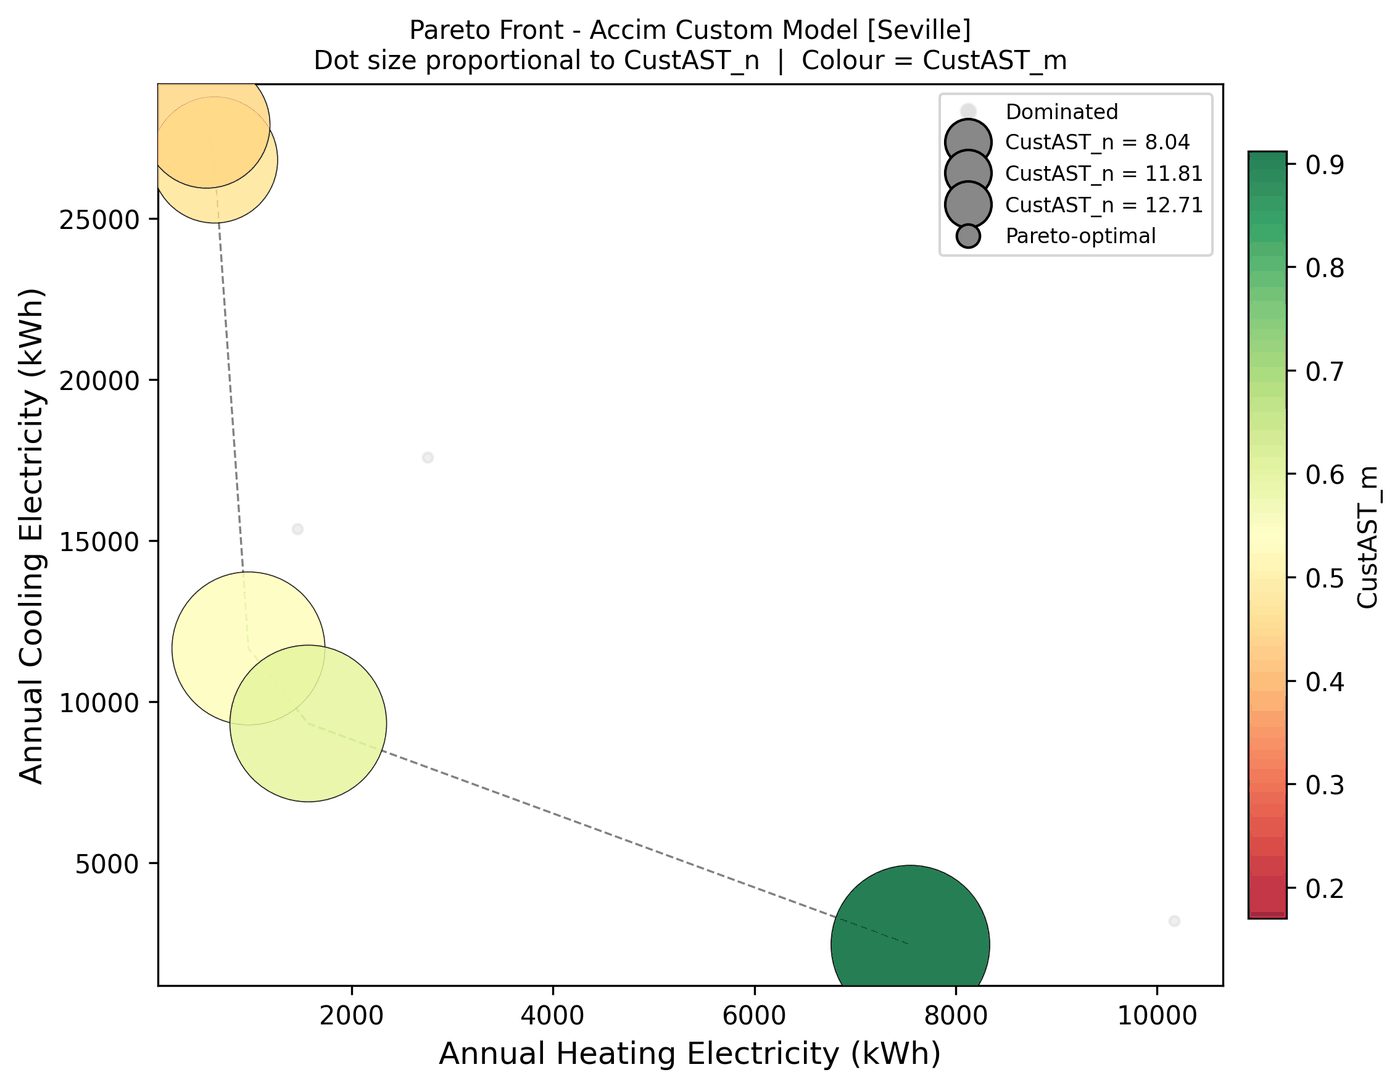

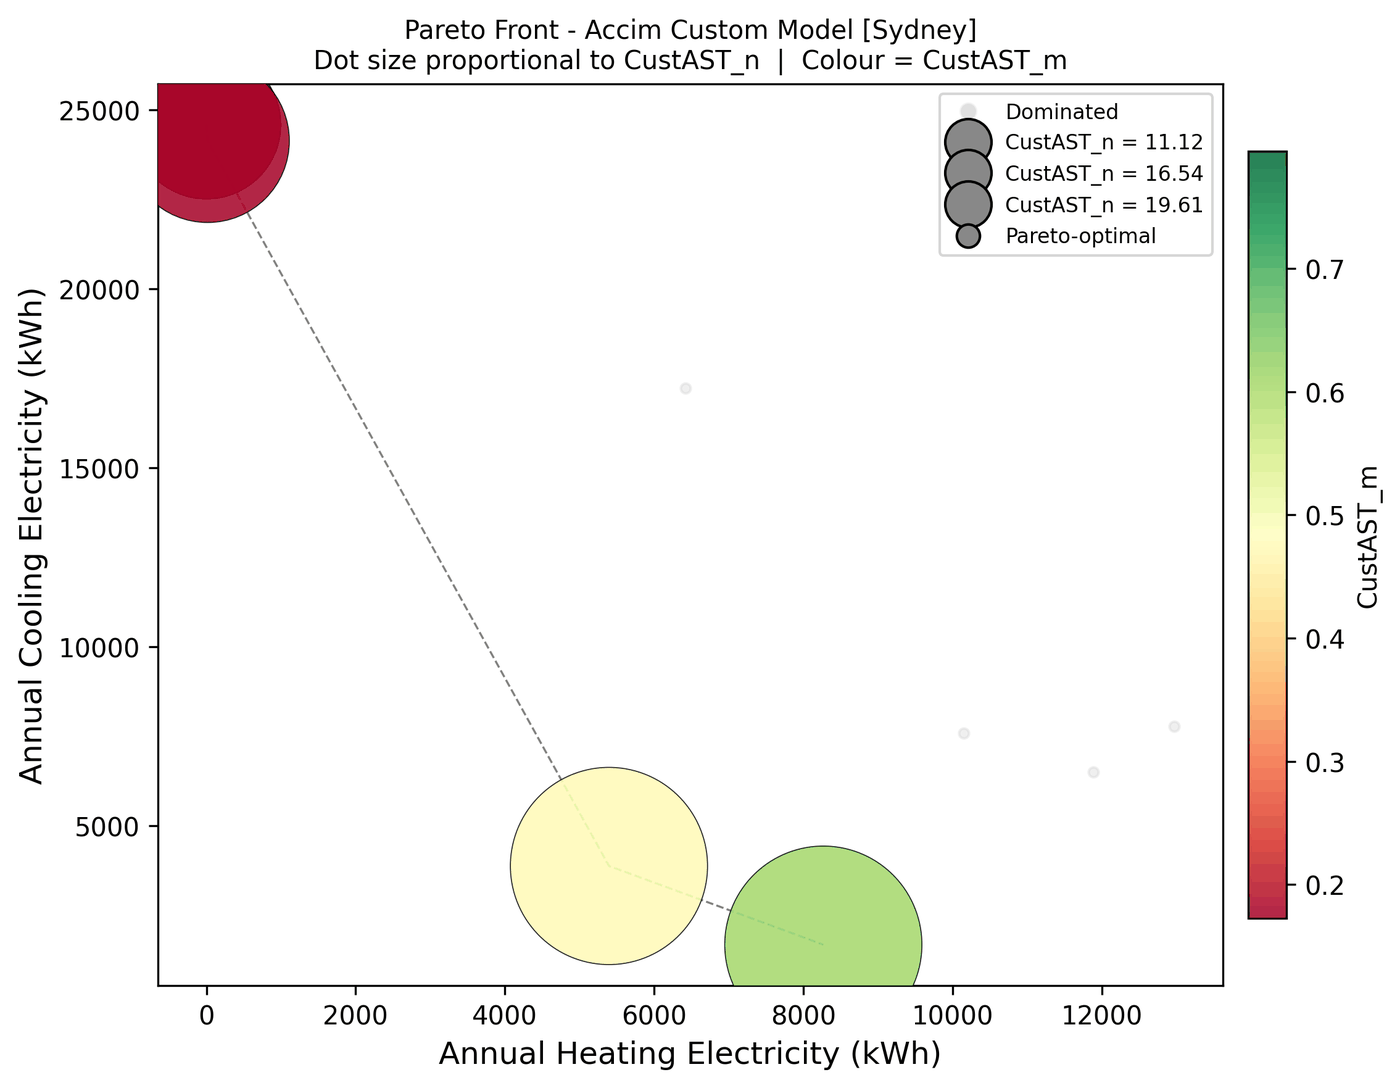

In [6]:

optim.plot_pareto_front(
    color_by="CustAST_m",
    size_by="CustAST_n",
    out_dir=RESULTS_DIRNAME,
    normalize_per_m2=False,
)
print("Pareto front plot generated.")

# Figures saved by plot_pareto_front, one per EPW.
for figure in sorted(Path(RESULTS_DIRNAME).glob("plot_pareto_front_*.png")):
    display(Image(filename=str(figure)))


### Reading the result

Check the figures above, also saved in the output folder: filters, grouping, and labels should match your intended interpretation.